# Notebook 06 — Advanced Tree-Based Models

## Objective

To evaluate advanced tree-based ensemble methods for DDoS detection
and compare their performance with the baseline models.

### Models

1. Gradient Boosting
2. HistGradientBoosting
3. XGBoost (if available)

### Evaluation

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Training time
- Confusion matrix

The same train/test split used in Notebook 05 will be maintained
for fair comparison.

In [30]:
import pandas as pd
import numpy as np
import time

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.ensemble import (
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [31]:
df = pd.read_csv("netguard_selected_features.csv")

print("Dataset shape:", df.shape)
print(df["Label"].value_counts())

Dataset shape: (223082, 21)
Label
DDoS      128014
BENIGN     95068
Name: count, dtype: int64


In [32]:
X = df.drop("Label", axis=1)
y = df["Label"]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)
print("Number of features:", X.shape[1])

Classes: ['BENIGN' 'DDoS']
Number of features: 20


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 178465
Testing samples : 44617


In [34]:
results = []

In [35]:
start_time = time.time()

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(
    X_train,
    y_train
)

training_time = time.time() - start_time

y_pred_gb = gb_model.predict(X_test)
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]



In [36]:
from sklearn.metrics import confusion_matrix

def calculate_fnr(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return fn / (fn + tp) * 100 if (fn + tp) > 0 else 0

In [37]:

fnr = calculate_fnr(y_test, y_pred_gb)

print(f"Gradient Boosting FNR: {fnr:.2f}%")

Gradient Boosting FNR: 0.05%


In [38]:
results.append({
    "Model": "Gradient Boosting",
    "Accuracy": accuracy_score(y_test, y_pred_gb),
    "Precision": precision_score(y_test, y_pred_gb),
    "Recall": recall_score(y_test, y_pred_gb),
    "F1": f1_score(y_test, y_pred_gb),
    "ROC-AUC": roc_auc_score(y_test, y_prob_gb),
    "Training Time": training_time,
    "FNR (%)": fnr
})

print("Gradient Boosting completed.")
print("Training time:", round(training_time, 2), "seconds")

Gradient Boosting completed.
Training time: 92.51 seconds


Gradient Boosting builds trees sequentially, where each new tree tries to correct errors made by previous trees.

Tree 1

  ↓

Errors

  ↓

Tree 2 learns from errors

  ↓

Errors

  ↓

Tree 3

  ↓

...

This is different from Random Forest, where trees are generally built independently and then combined.

In [39]:
start_time = time.time()

hgb_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

hgb_model.fit(
    X_train,
    y_train
)

training_time = time.time() - start_time

y_pred_hgb = hgb_model.predict(X_test)
y_prob_hgb = hgb_model.predict_proba(X_test)[:, 1]



In [40]:
from sklearn.metrics import confusion_matrix

def calculate_fnr(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return fn / (fn + tp) * 100 if (fn + tp) > 0 else 0

In [41]:

fnr = calculate_fnr(y_test,y_pred_hgb)

print(f"HistGradientBoosting FNR: {fnr:.2f}%")

HistGradientBoosting FNR: 0.00%


In [42]:
results.append({
    "Model": "HistGradientBoosting",
    "Accuracy": accuracy_score(y_test, y_pred_hgb),
    "Precision": precision_score(y_test, y_pred_hgb),
    "Recall": recall_score(y_test, y_pred_hgb),
    "F1": f1_score(y_test, y_pred_hgb),
    "ROC-AUC": roc_auc_score(y_test, y_prob_hgb),
    "Training Time": training_time,
    "FNR (%)": fnr
})

print("HistGradientBoosting completed.")
print("Training time:", round(training_time, 2), "seconds")

HistGradientBoosting completed.
Training time: 2.34 seconds


In [43]:
boosting_results = pd.DataFrame(results)

boosting_results.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time,FNR (%)
0,Gradient Boosting,0.9997,0.9999,0.9995,0.9997,1.0,92.5130,0.0469
1,HistGradientBoosting,1.0000,1.0000,1.0000,1.0000,1.0,2.3356,0.0039


In [44]:
try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)
    xgboost_available = True

except ImportError:
    print("XGBoost is not installed.")
    xgboost_available = False

XGBoost version: 3.2.0


In [45]:
!pip install xgboost


[notice] A new release of pip available: 22.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
if xgboost_available:

    start_time = time.time()

    xgb_model = xgb.XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss"
    )

    xgb_model.fit(
        X_train,
        y_train
    )

    training_time = time.time() - start_time

    y_pred_xgb = xgb_model.predict(X_test)
    y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

    

In [47]:
from sklearn.metrics import confusion_matrix

def calculate_fnr(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return fn / (fn + tp) * 100 if (fn + tp) > 0 else 0

In [48]:

fnr = calculate_fnr(y_test, y_pred_xgb)

print(f"XGBoost FNR: {fnr:.2f}%")

XGBoost FNR: 0.00%


In [49]:
results.append({
        "Model": "XGBoost",
        "Accuracy": accuracy_score(y_test, y_pred_xgb),
        "Precision": precision_score(y_test, y_pred_xgb),
        "Recall": recall_score(y_test, y_pred_xgb),
        "F1": f1_score(y_test, y_pred_xgb),
        "ROC-AUC": roc_auc_score(y_test, y_prob_xgb),
        "Training Time": training_time,
        "FNR (%)": fnr
    })

print("XGBoost completed.")
print("Training time:", round(training_time, 2), "seconds")

XGBoost completed.
Training time: 1.19 seconds


In [50]:
results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time,FNR (%)
0,Gradient Boosting,0.9997,0.9999,0.9995,0.9997,1.0,92.5130,0.0469
1,HistGradientBoosting,1.0000,1.0000,1.0000,1.0000,1.0,2.3356,0.0039
2,XGBoost,0.9999,0.9999,1.0000,0.9999,1.0,1.1935,0.0039


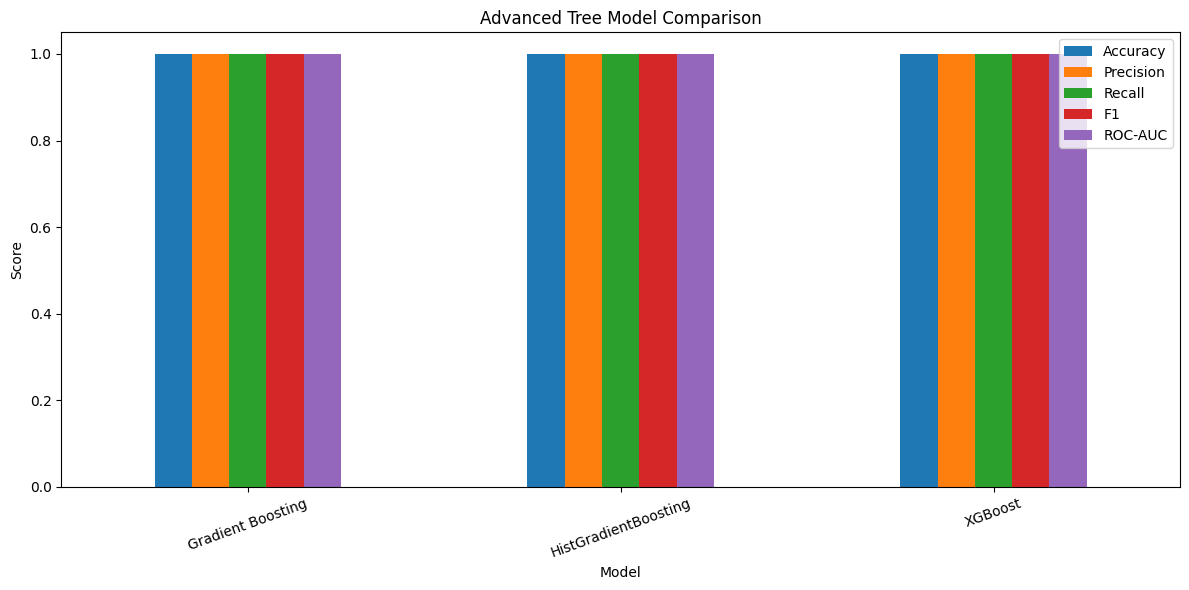

In [51]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Advanced Tree Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

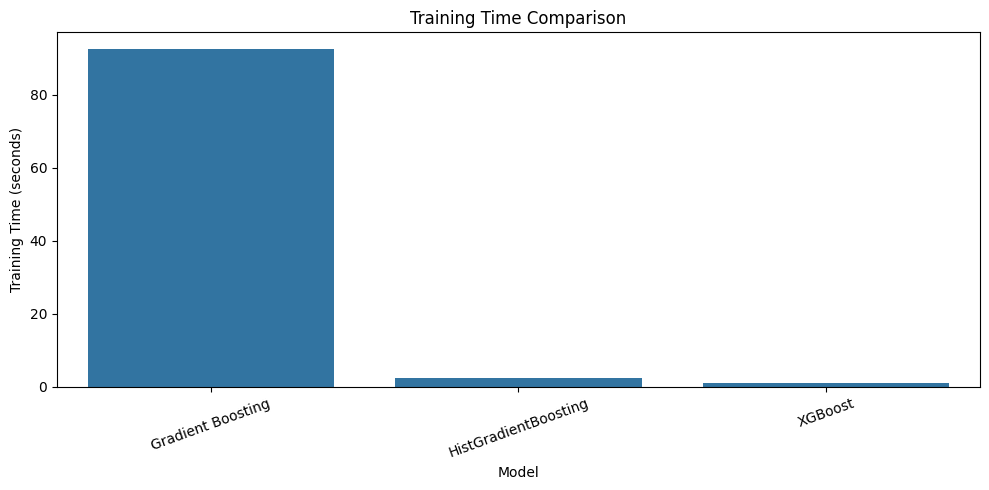

In [52]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Training Time"
)

plt.title("Training Time Comparison")
plt.ylabel("Training Time (seconds)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

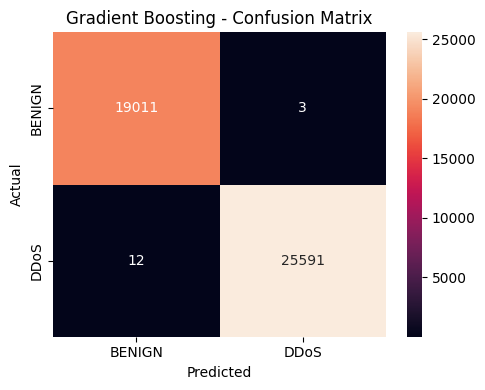

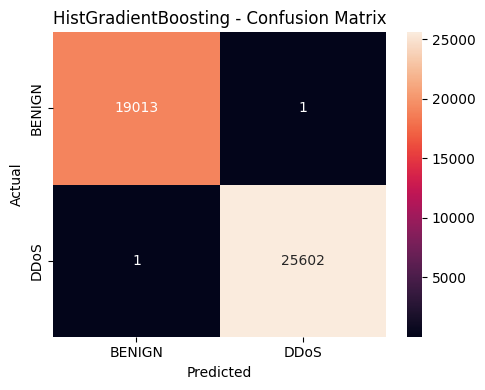

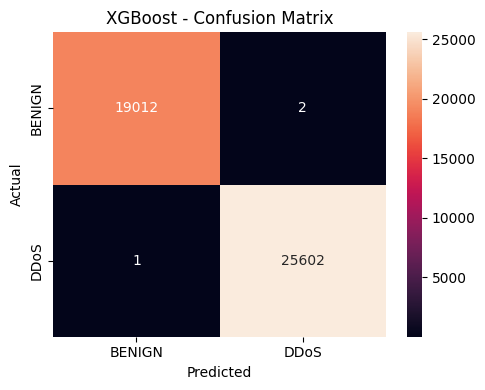

In [53]:
predictions = {
    "Gradient Boosting": y_pred_gb,
    "HistGradientBoosting": y_pred_hgb
}

if xgboost_available:
    predictions["XGBoost"] = y_pred_xgb


for model_name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.show()

In [54]:
for model_name, y_pred in predictions.items():

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=label_encoder.classes_
        )
    )


Gradient Boosting
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     19014
        DDoS       1.00      1.00      1.00     25603

    accuracy                           1.00     44617
   macro avg       1.00      1.00      1.00     44617
weighted avg       1.00      1.00      1.00     44617


HistGradientBoosting
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     19014
        DDoS       1.00      1.00      1.00     25603

    accuracy                           1.00     44617
   macro avg       1.00      1.00      1.00     44617
weighted avg       1.00      1.00      1.00     44617


XGBoost
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     19014
        DDoS       1.00      1.00      1.00     25603

    accuracy                           1.00     44617
   macro avg       1.00      1.00      1.00     44617
weighted avg       1.00 

In [55]:
train_predictions = {
    "Gradient Boosting": gb_model.predict(X_train),
    "HistGradientBoosting": hgb_model.predict(X_train)
}

if xgboost_available:
    train_predictions["XGBoost"] = xgb_model.predict(X_train)


for model_name, train_pred in train_predictions.items():

    test_pred = predictions[model_name]

    train_accuracy = accuracy_score(
        y_train,
        train_pred
    )

    test_accuracy = accuracy_score(
        y_test,
        test_pred
    )

    print("\n", model_name)
    print("Train Accuracy:", round(train_accuracy, 6))
    print("Test Accuracy :", round(test_accuracy, 6))
    print(
        "Train-Test Gap:",
        round(train_accuracy - test_accuracy, 6)
    )


 Gradient Boosting
Train Accuracy: 0.999765
Test Accuracy : 0.999664
Train-Test Gap: 0.000101

 HistGradientBoosting
Train Accuracy: 0.999978
Test Accuracy : 0.999955
Train-Test Gap: 2.2e-05

 XGBoost
Train Accuracy: 0.999966
Test Accuracy : 0.999933
Train-Test Gap: 3.4e-05


In [56]:
results_df.to_csv(
    "advanced_tree_model_results.csv",
    index=False
)

print("Advanced tree model results saved.")

Advanced tree model results saved.


# Conclusion

Advanced tree-based ensemble models were evaluated for DDoS detection.

Gradient Boosting, HistGradientBoosting, and XGBoost (when available)
were compared using the same train/test split and evaluation metrics
as the baseline models.

The comparison considered both predictive performance and
computational cost.

Train-test performance was also examined to identify possible
overfitting.

The results will be combined with the baseline models in the
overall model-comparison stage.